<a href="https://colab.research.google.com/github/athirr-hub/Project_AI/blob/main/Lungcancer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Preprocessing dan Klasifikasi Random Forest — Prediksi Kanker Paru (Lung Cancer)

Notebook ini berisi tahapan preprocessing pada dataset `datasetlung1.csv`, dilanjutkan training dan evaluasi model klasifikasi Random Forest.

**Alur preprocessing:**
1. Import library
2. Load dataset
3. Data understanding
4. Data cleaning (missing value, duplikat)
5. Visualisasi Data
6. Encoding / transformasi data
7. Analisis korelasi
8. Pemisahan fitur–target dan split train–test (kolom `LUNG_CANCER` tetap dipertahankan)
9. Training model Random Forest
10. Evaluasi model
11. Inference

## 1. Import Library

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import chi2, mutual_info_classif

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)
RANDOM_STATE = 42

## 2. Load Dataset

Jalankan sel di bawah, lalu upload file `datasetlung1.csv` saat diminta (di Google Colab).

In [ ]:
try:
    from google.colab import files
    files.upload()          # pilih datasetlung1.csv
except ImportError:
    pass                    # jika dijalankan lokal, file dibaca dari folder yang sama

df = pd.read_csv('/content/datasetlung1.csv')
print('Jumlah baris  :', df.shape[0])
print('Jumlah kolom  :', df.shape[1])
df.head(1)

Saving datasetlung1.csv to datasetlung1 (2).csv
Jumlah baris  : 3000
Jumlah kolom  : 16


,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC_DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL_CONSUMING,COUGHING,SHORTNESS_OF_BREATH,SWALLOWING_DIFFICULTY,CHEST_PAIN,LUNG_CANCER
0,M,65,1,1,1,2,2,1,2,2,2,2,2,2,1,NO


## 3. Data Understanding

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   GENDER                 3000 non-null   object
 1   AGE                    3000 non-null   int64 
 2   SMOKING                3000 non-null   int64 
 3   YELLOW_FINGERS         3000 non-null   int64 
 4   ANXIETY                3000 non-null   int64 
 5   PEER_PRESSURE          3000 non-null   int64 
 6   CHRONIC_DISEASE        3000 non-null   int64 
 7   FATIGUE                3000 non-null   int64 
 8   ALLERGY                3000 non-null   int64 
 9   WHEEZING               3000 non-null   int64 
 10  ALCOHOL_CONSUMING      3000 non-null   int64 
 11  COUGHING               3000 non-null   int64 
 12  SHORTNESS_OF_BREATH    3000 non-null   int64 
 13  SWALLOWING_DIFFICULTY  3000 non-null   int64 
 14  CHEST_PAIN             3000 non-null   int64 
 15  LUNG_CANCER          

In [ ]:
# Statistik deskriptif untuk seluruh kolom
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
GENDER,3000,2,M,1514,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AGE,3000.0,NaN,NaN,NaN,55.169,14.723746,30.0,42.0,55.0,68.0,80.0
SMOKING,3000.0,NaN,NaN,NaN,1.491,0.500002,1.0,1.0,1.0,2.0,2.0
YELLOW_FINGERS,3000.0,NaN,NaN,NaN,1.514,0.499887,1.0,1.0,2.0,2.0,2.0
ANXIETY,3000.0,NaN,NaN,NaN,1.494,0.500047,1.0,1.0,1.0,2.0,2.0
PEER_PRESSURE,3000.0,NaN,NaN,NaN,1.499,0.500082,1.0,1.0,1.0,2.0,2.0
CHRONIC_DISEASE,3000.0,NaN,NaN,NaN,1.509667,0.49999,1.0,1.0,2.0,2.0,2.0
FATIGUE,3000.0,NaN,NaN,NaN,1.489667,0.499977,1.0,1.0,1.0,2.0,2.0
ALLERGY,3000.0,NaN,NaN,NaN,1.506667,0.500039,1.0,1.0,2.0,2.0,2.0
WHEEZING,3000.0,NaN,NaN,NaN,1.497333,0.500076,1.0,1.0,1.0,2.0,2.0


In [ ]:
# Jumlah nilai unik dan daftar nilai pada tiap kolom (HAPUSS??)
for col in df.columns:
    n = df[col].nunique()
    if n <= 10:
        print(f'{col:<25} ({n} unik) -> {sorted(df[col].unique())}')
    else:
        print(f'{col:<25} ({n} unik) -> rentang {df[col].min()} s.d. {df[col].max()}')

GENDER                    (2 unik) -> ['F', 'M']
AGE                       (51 unik) -> rentang 30 s.d. 80
SMOKING                   (2 unik) -> [np.int64(1), np.int64(2)]
YELLOW_FINGERS            (2 unik) -> [np.int64(1), np.int64(2)]
ANXIETY                   (2 unik) -> [np.int64(1), np.int64(2)]
PEER_PRESSURE             (2 unik) -> [np.int64(1), np.int64(2)]
CHRONIC_DISEASE           (2 unik) -> [np.int64(1), np.int64(2)]
FATIGUE                   (2 unik) -> [np.int64(1), np.int64(2)]
ALLERGY                   (2 unik) -> [np.int64(1), np.int64(2)]
WHEEZING                  (2 unik) -> [np.int64(1), np.int64(2)]
ALCOHOL_CONSUMING         (2 unik) -> [np.int64(1), np.int64(2)]
COUGHING                  (2 unik) -> [np.int64(1), np.int64(2)]
SHORTNESS_OF_BREATH       (2 unik) -> [np.int64(1), np.int64(2)]
SWALLOWING_DIFFICULTY     (2 unik) -> [np.int64(1), np.int64(2)]
CHEST_PAIN                (2 unik) -> [np.int64(1), np.int64(2)]
LUNG_CANCER               (2 unik) -> ['NO', 'YE

**Keterangan kolom**

| Kolom | Tipe | Keterangan |
|---|---|---|
| GENDER | kategorik | M = laki-laki, F = perempuan |
| AGE | numerik | Usia (tahun) |
| SMOKING s.d. CHEST_PAIN (13 kolom) | biner | 1 = Tidak, 2 = Ya |
| LUNG_CANCER | target | YES / NO |

## 4. Data Cleaning

### 4.1 Standarisasi nama kolom dan teks

In [ ]:
# Hilangkan spasi berlebih pada nama kolom
df.columns = df.columns.str.strip().str.upper().str.replace(' ', '_')

# Hilangkan spasi berlebih dan samakan huruf kapital pada kolom teks
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip().str.upper()

print(df.columns.tolist())

['GENDER', 'AGE', 'SMOKING', 'YELLOW_FINGERS', 'ANXIETY', 'PEER_PRESSURE', 'CHRONIC_DISEASE', 'FATIGUE', 'ALLERGY', 'WHEEZING', 'ALCOHOL_CONSUMING', 'COUGHING', 'SHORTNESS_OF_BREATH', 'SWALLOWING_DIFFICULTY', 'CHEST_PAIN', 'LUNG_CANCER']


### 4.2 Pengecekan missing value

In [ ]:
missing = pd.DataFrame({
    'jumlah_missing': df.isnull().sum(),
    'persen': (df.isnull().mean() * 100).round(2)
})
print(missing)
print('\nTotal missing value:', df.isnull().sum().sum())

                       jumlah_missing  persen
GENDER                              0     0.0
AGE                                 0     0.0
SMOKING                             0     0.0
YELLOW_FINGERS                      0     0.0
ANXIETY                             0     0.0
PEER_PRESSURE                       0     0.0
CHRONIC_DISEASE                     0     0.0
FATIGUE                             0     0.0
ALLERGY                             0     0.0
WHEEZING                            0     0.0
ALCOHOL_CONSUMING                   0     0.0
COUGHING                            0     0.0
SHORTNESS_OF_BREATH                 0     0.0
SWALLOWING_DIFFICULTY               0     0.0
CHEST_PAIN                          0     0.0
LUNG_CANCER                         0     0.0

Total missing value: 0


### 4.3 Pengecekan dan penghapusan data duplikat

In [ ]:
n_dup = df.duplicated().sum()
print('Jumlah baris duplikat :', n_dup)

if n_dup > 0:
    display(df[df.duplicated(keep=False)].sort_values(list(df.columns)))

Jumlah baris duplikat : 2


,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC_DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL_CONSUMING,COUGHING,SHORTNESS_OF_BREATH,SWALLOWING_DIFFICULTY,CHEST_PAIN,LUNG_CANCER
1051,M,50,1,1,1,2,1,2,1,2,2,2,2,1,2,YES
2039,M,50,1,1,1,2,1,2,1,2,2,2,2,1,2,YES
962,M,53,1,2,2,2,2,1,1,1,1,2,2,1,2,NO
1476,M,53,1,2,2,2,2,1,1,1,1,2,2,1,2,NO


In [ ]:
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f'Baris sebelum : {before}')
print(f'Baris sesudah : {len(df)}')
print(f'Terhapus      : {before - len(df)}')

Baris sebelum : 3000
Baris sesudah : 2998
Terhapus      : 2


## 5. Visualisasi Data

### 5.1 Distribusi target

LUNG_CANCER
YES    1517
NO     1481
Name: count, dtype: int64
LUNG_CANCER
YES    50.6
NO     49.4
Name: proportion, dtype: float64


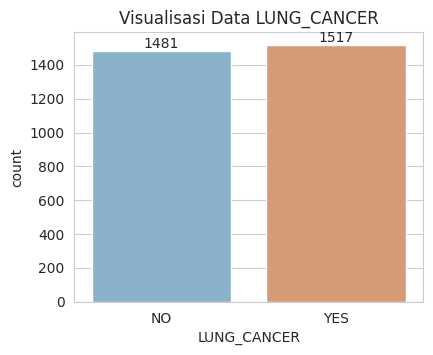

In [ ]:
target_count = df['LUNG_CANCER'].value_counts()
print(target_count)
print((df['LUNG_CANCER'].value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(4.5, 3.5))
ax = sns.countplot(x='LUNG_CANCER', data=df, palette=['#7fb3d5', '#e59866'])
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom')
plt.title('Visualisasi Data LUNG_CANCER')
plt.show()

## 6. Encoding / Transformasi Data

Dataset ini memakai kode **1 = Tidak, 2 = Ya** untuk fitur biner. Agar konvensional dan mudah diinterpretasi, kode diubah menjadi **0 = Tidak, 1 = Ya**.

- Fitur biner (1/2) → 0/1
- `GENDER`: F = 0, M = 1
- `LUNG_CANCER` (target): NO = 0, YES = 1

In [ ]:
df_clean = df.copy()

# Fitur biner: 1 -> 0 (Tidak), 2 -> 1 (Ya)
for col in biner_cols:
    df_clean[col] = df_clean[col].map({1: 0, 2: 1})

# GENDER
df_clean['GENDER'] = df_clean['GENDER'].map({'F': 0, 'M': 1})

# Target
df_clean['LUNG_CANCER'] = df_clean['LUNG_CANCER'].map({'NO': 0, 'YES': 1})

print('Sisa missing value setelah encoding:', df_clean.isnull().sum().sum())
print(df_clean.dtypes)
df_clean.head()

Sisa missing value setelah encoding: 0
GENDER                   int64
AGE                      int64
SMOKING                  int64
YELLOW_FINGERS           int64
ANXIETY                  int64
PEER_PRESSURE            int64
CHRONIC_DISEASE          int64
FATIGUE                  int64
ALLERGY                  int64
WHEEZING                 int64
ALCOHOL_CONSUMING        int64
COUGHING                 int64
SHORTNESS_OF_BREATH      int64
SWALLOWING_DIFFICULTY    int64
CHEST_PAIN               int64
LUNG_CANCER              int64
dtype: object


,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC_DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL_CONSUMING,COUGHING,SHORTNESS_OF_BREATH,SWALLOWING_DIFFICULTY,CHEST_PAIN,LUNG_CANCER
0,1,65,0,0,0,1,1,0,1,1,1,1,1,1,0,0
1,0,55,0,1,1,0,0,1,1,1,0,0,0,1,1,0
2,0,78,1,1,0,0,0,1,0,1,0,0,1,0,0,1
3,1,60,1,0,0,0,1,0,1,0,0,1,0,1,1,1
4,0,80,0,0,1,0,0,1,0,1,0,0,0,0,1,0


## 7. Analisis Korelasi dan Seleksi Fitur

### 7.1 Heatmap korelasi

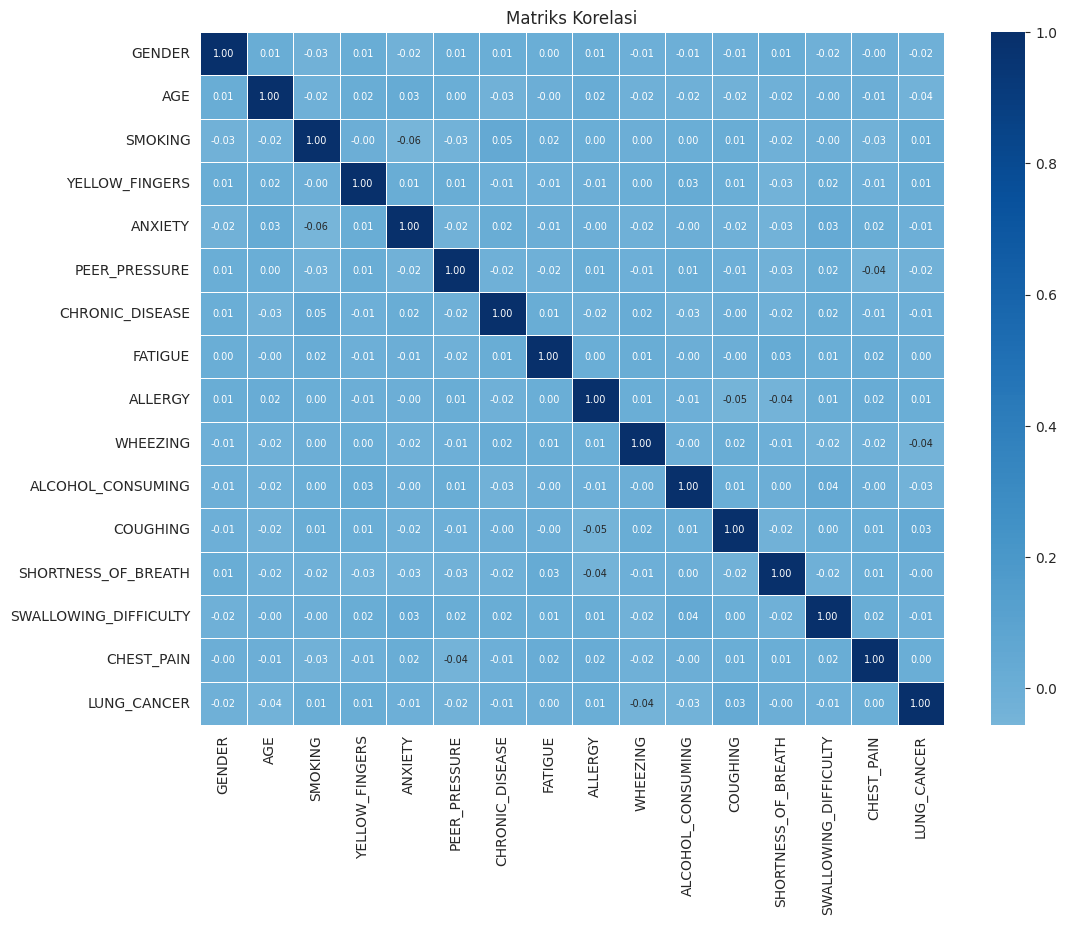

In [ ]:
plt.figure(figsize=(12, 9))

sns.heatmap(df_clean.corr(), annot=True, fmt='.2f', cmap='Blues',
            center=0, linewidths=0.5, annot_kws={'size': 7})

plt.title('Matriks Korelasi')
plt.show()

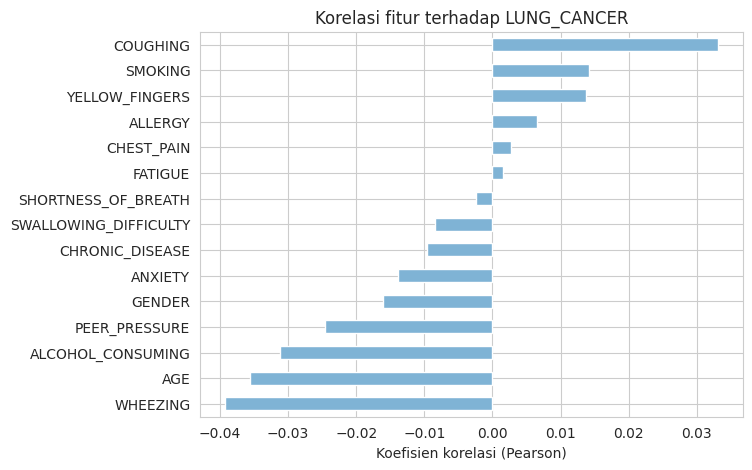

WHEEZING                -0.0393
AGE                     -0.0357
ALCOHOL_CONSUMING       -0.0312
PEER_PRESSURE           -0.0247
GENDER                  -0.0161
ANXIETY                 -0.0139
CHRONIC_DISEASE         -0.0096
SWALLOWING_DIFFICULTY   -0.0084
SHORTNESS_OF_BREATH     -0.0024
FATIGUE                  0.0016
CHEST_PAIN               0.0027
ALLERGY                  0.0065
YELLOW_FINGERS           0.0137
SMOKING                  0.0142
COUGHING                 0.0331
Name: LUNG_CANCER, dtype: float64


In [ ]:
# Korelasi tiap fitur terhadap target
korelasi_target = df_clean.corr()['LUNG_CANCER'].drop('LUNG_CANCER').sort_values()

plt.figure(figsize=(7, 5))
korelasi_target.plot(kind='barh', color='#7fb3d5')
plt.title('Korelasi fitur terhadap LUNG_CANCER')
plt.xlabel('Koefisien korelasi (Pearson)')
plt.show()

print(korelasi_target.round(4))

# 7.2 Simpan Hasil Preprocessing

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split # Keep import for consistency if needed elsewhere
from sklearn.preprocessing import StandardScaler # Keep import for consistency if needed elsewhere
import joblib # Keep import for consistency if needed elsewhere

# 1. Simpan dataset bersih (sebelum split & scaling)
df_clean.to_csv('lung_cancer_clean.csv', index=False)

# Kode untuk pemisahan data (X_train, y_train, X_test, y_test) telah dipindahkan ke sel lain.
# Variabel tersebut akan didefinisikan di sana untuk keperluan training model.

print('File tersimpan: lung_cancer_clean.csv')

# 2. Unduh otomatis jika dijalankan di Google Colab
try:
    from google.colab import files
    for f in ['lung_cancer_clean.csv']:
        files.download(f)
except ImportError:
    pass

File tersimpan: lung_cancer_clean.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. Pemisahan Fitur–Target dan Split Data

*(Catatan: Langkah pemisahan fitur-target dan split data ini sekarang dilakukan di sel Python di bawah ini untuk memastikan ketersediaan variabel sebelum training model.)*

In [ ]:
# Variabel global RANDOM_STATE sudah didefinisikan di awal notebook.

target_col   = 'LUNG_CANCER'
feature_cols = [c for c in df_clean.columns if c != target_col]

X = df_clean[feature_cols].copy()   # fitur (15 kolom)
y = df_clean[target_col].copy()     # target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print('X_train:', X_train.shape, '| X_test:', X_test.shape)
print('Proporsi target (train):'); print(y_train.value_counts(normalize=True).round(3))
print('Proporsi target (test):');  print(y_test.value_counts(normalize=True).round(3))

# Pastikan kolom LUNG_CANCER di df_clean masih utuh
print('LUNG_CANCER masih ada di df_clean:', target_col in df_clean.columns, '| shape df_clean:', df_clean.shape)

X_train: (2398, 15) | X_test: (600, 15)
Proporsi target (train):
LUNG_CANCER
1    0.506
0    0.494
Name: proportion, dtype: float64
Proporsi target (test):
LUNG_CANCER
1    0.507
0    0.493
Name: proportion, dtype: float64
LUNG_CANCER masih ada di df_clean: True | shape df_clean: (2998, 16)


Kolom `LUNG_CANCER` **tetap ada** di `df_clean` (tidak dihapus). Untuk keperluan model, fitur dan target hanya diambil sebagai salinan terpisah (`X` dan `y`), sehingga `df_clean` tidak berubah.

Split memakai `stratify=y` agar proporsi kelas pada data latih dan data uji sama. Scaling tidak diperlukan karena Random Forest berbasis pohon keputusan dan tidak sensitif terhadap skala fitur.


# TRAINING

## 9. Training Model Random Forest

### 9.1 Model baseline

In [ ]:
from sklearn.ensemble import RandomForestClassifier
rf_base = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
rf_base.fit(X_train, y_train)
print('Model baseline selesai dilatih.')

Model baseline selesai dilatih.


### 9.2 Model final

In [ ]:
rf_final = rf_base      # model baseline digunakan sebagai model final

joblib.dump(rf_final, 'rf_lung_cancer.pkl')
print('Model final tersimpan: rf_lung_cancer.pkl')

Model final tersimpan: rf_lung_cancer.pkl


---
# EVALUASI

## 10. Evaluasi Model

### 10.1 Perbandingan metrik pada data uji

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

def hitung_metrik(model, X_, y_):
    pred  = model.predict(X_)
    proba = model.predict_proba(X_)[:, 1]
    return {
        'Accuracy' : accuracy_score(y_, pred),
        'Precision': precision_score(y_, pred),
        'Recall'   : recall_score(y_, pred),
        'F1-score' : f1_score(y_, pred),
    }

hasil = pd.DataFrame({
    'Random Forest (baseline)': hitung_metrik(rf_final, X_test, y_test),
}).T.round(4)
hasil

,Accuracy,Precision,Recall,F1-score
Random Forest (baseline),0.56,0.5645,0.5757,0.57


### 10.2 Classification report (model final)

In [ ]:
from sklearn.metrics import classification_report

y_pred  = rf_final.predict(X_test)
y_proba = rf_final.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, target_names=['NO (0)', 'YES (1)']))

              precision    recall  f1-score   support

      NO (0)       0.56      0.54      0.55       296
     YES (1)       0.56      0.58      0.57       304

    accuracy                           0.56       600
   macro avg       0.56      0.56      0.56       600
weighted avg       0.56      0.56      0.56       600



### 10.3 Confusion matrix

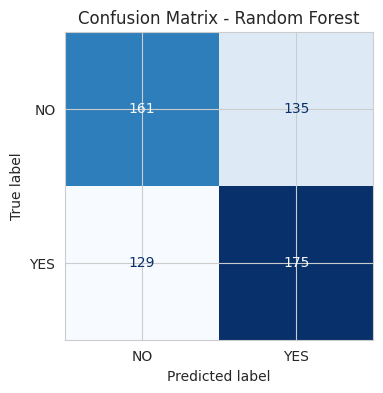

TN=161 | FP=135 | FN=129 | TP=175


In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(4.8, 4))
ConfusionMatrixDisplay(cm, display_labels=['NO', 'YES']).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Confusion Matrix - Random Forest')
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'TN={tn} | FP={fp} | FN={fn} | TP={tp}')

### 10.4 Feature importance

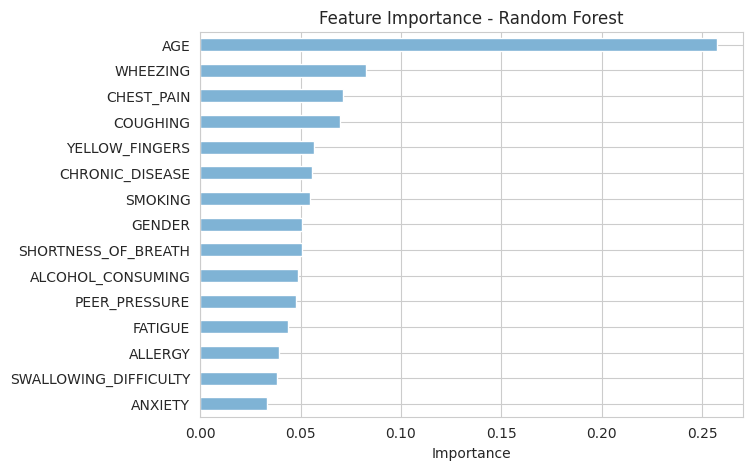

,0
AGE,0.2573
WHEEZING,0.0824
CHEST_PAIN,0.0710
COUGHING,0.0694
YELLOW_FINGERS,0.0566
CHRONIC_DISEASE,0.0559
SMOKING,0.0548
GENDER,0.0509
SHORTNESS_OF_BREATH,0.0509
ALCOHOL_CONSUMING,0.0487


In [ ]:
importance = pd.Series(rf_final.feature_importances_, index=X_train.columns).sort_values()

plt.figure(figsize=(7, 5))
importance.plot(kind='barh', color='#7fb3d5')
plt.title('Feature Importance - Random Forest')
plt.xlabel('Importance')
plt.show()

importance.sort_values(ascending=False).round(4)

### 10.5 Pengecekan overfitting (train vs test)

In [ ]:
from sklearn.metrics import accuracy_score

acc_train = accuracy_score(y_train, rf_final.predict(X_train))
acc_test  = accuracy_score(y_test,  y_pred)

print(f'Akurasi data latih : {acc_train:.4f}')
print(f'Akurasi data uji   : {acc_test:.4f}')
print(f'Selisih            : {acc_train - acc_test:.4f}')

Akurasi data latih : 0.5742
Akurasi data uji   : 0.5600
Selisih            : 0.0142



### 11. INFERENCE


In [ ]:
import pandas as pd
import joblib

# 1. Load model final (hasil training di notebook)
model = joblib.load('rf_lung_cancer.pkl')

# 2. Data pasien baru (1 = Tidak, 2 = Ya)
pasien = pd.DataFrame([{
    'GENDER': 'M', 'AGE': 67, 'SMOKING': 2, 'YELLOW_FINGERS': 2,
    'ANXIETY': 1, 'PEER_PRESSURE': 1, 'CHRONIC_DISEASE': 2, 'FATIGUE': 2,
    'ALLERGY': 1, 'WHEEZING': 2, 'ALCOHOL_CONSUMING': 1, 'COUGHING': 2,
    'SHORTNESS_OF_BREATH': 2, 'SWALLOWING_DIFFICULTY': 1, 'CHEST_PAIN': 2,
}])

# 3. Preprocessing: samakan dengan saat training
pasien['GENDER'] = pasien['GENDER'].map({'F': 0, 'M': 1})
pasien = pasien[model.feature_names_in_]      # urutan kolom sama dengan training

# 4. Prediksi
pred  = model.predict(pasien)[0]
proba = model.predict_proba(pasien)[0]

print('Prediksi    :', 'YES (berisiko kanker paru)' if pred == 1 else 'NO (tidak berisiko)')
print(f'Probabilitas: NO={proba[0]:.2%} | YES={proba[1]:.2%}')

Prediksi    : NO (tidak berisiko)
Probabilitas: NO=50.35% | YES=49.65%


### Ringkasan

In [ ]:

print('RINGKASAN\n')

print(f'Data setelah cleaning : {df_clean.shape[0]} baris, {df_clean.shape[1]} kolom (LUNG_CANCER tetap ada)')
print(f'Data latih / uji      : {len(X_train)} / {len(X_test)}')
print(f'Akurasi CV (baseline) : {cv_acc.mean():.4f}')
print(f'Akurasi uji (final)   : {acc_test:.4f}')
print(f'F1-score uji (final)  : {f1_score(y_test, y_pred):.4f}')


RINGKASAN

Data setelah cleaning : 2998 baris, 16 kolom (LUNG_CANCER tetap ada)
Data latih / uji      : 2400 / 600
Akurasi CV (baseline) : 0.5075
Akurasi uji (final)   : 0.5600
F1-score uji (final)  : 0.5700
